# Homogenization — four different checks

The first diversity notebook was mostly “average entropy/TTR by month.” That is useful, but it is not really four separate homogenization questions. Advisors asked for something closer to this:

1. **Inside one post** — is the vocabulary getting flatter?
2. **Across posts, words** — are posts recycling the same words?
3. **Across posts, meaning** — are posts saying more similar things?
4. **Topics** — is the mix of topics getting narrower?

We built one monthly file per platform for those (`data/homogenization/`). Text measures use a sample of about 300 posts per month. Topic entropy uses every post that month. AI means `P_AI ≥ 0.5`. Break is still Dec 2022.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 11,
})

ROOT = Path("/Users/kofibadu/Desktop/cap folder")
HOMO = ROOT / "data" / "homogenization"
CUT = "2022-12"
COLORS = {"medium": "#c45c26", "substack": "#1b3a4b"}

def load(platform):
    df = pd.read_csv(HOMO / f"{platform}_monthly_homogenization.csv")
    df["platform"] = platform
    df["period"] = np.where(df["year_month"] >= CUT, "post", "pre")
    df["date"] = pd.to_datetime(df["year_month"])
    return df

month = pd.concat([load("medium"), load("substack")], ignore_index=True)
print(month.groupby("platform")[["n_posts", "n_ai"]].sum())


          n_posts    n_ai
platform                 
medium     350000  129018
substack   350000   37025


## 1. Topic mix

This one does not need the article text. We just look at `topic_code` each month. If things were homogenizing, topic entropy should fall and the Herfindahl (HHI) should rise.


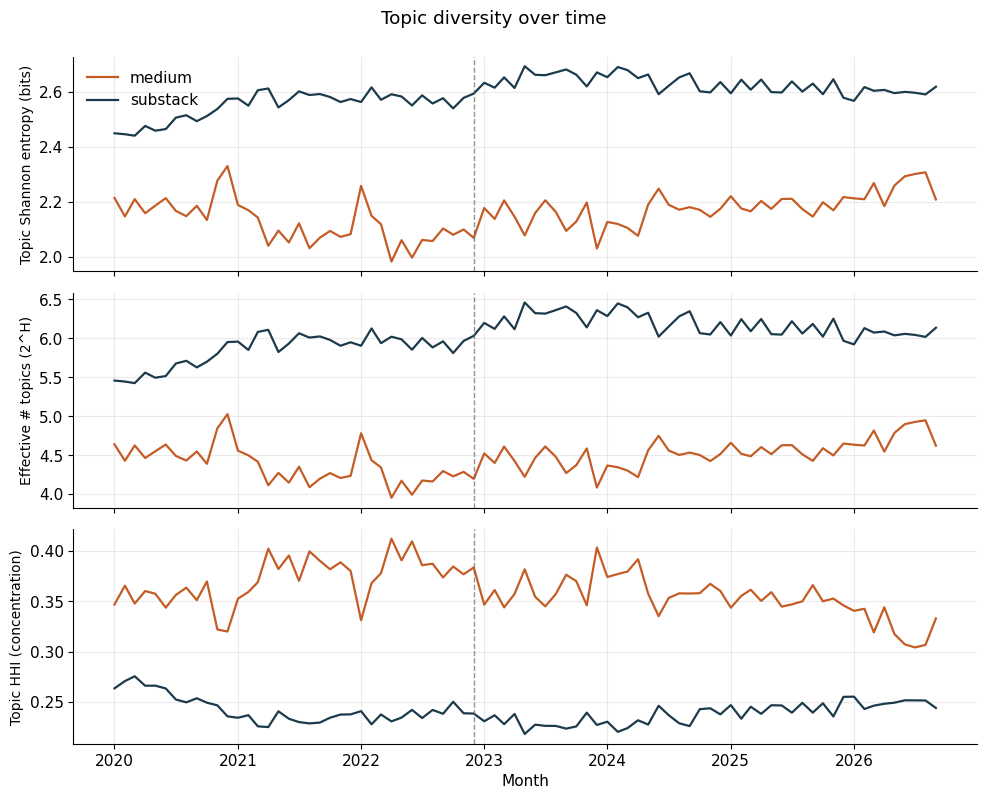

topic_entropy  topic_effective_n  topic_hhi  share_ai
platform period                                                       
medium   post           2.1774             4.5271     0.3530    0.6161
         pre            2.1277             4.3765     0.3706    0.0051
substack post           2.6273             6.1802     0.2379    0.1695
         pre            2.5460             5.8437     0.2429    0.0016

In [2]:
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
for ax, col, title in zip(
    axes,
    ["topic_entropy", "topic_effective_n", "topic_hhi"],
    ["Topic Shannon entropy (bits)", "Effective # topics (2^H)", "Topic HHI (concentration)"],
):
    for platform, g in month.groupby("platform"):
        ax.plot(g["date"], g[col], label=platform, color=COLORS[platform], lw=1.6)
    ax.axvline(pd.Timestamp("2022-12-01"), color="#666", ls="--", lw=1, alpha=0.7)
    ax.set_ylabel(title, fontsize=10)
axes[0].legend(frameon=False)
axes[-1].set_xlabel("Month")
fig.suptitle("Topic mix over time", y=0.995)
fig.tight_layout()
plt.show()

display(
    month.groupby(["platform", "period"])[["topic_entropy", "topic_effective_n", "topic_hhi", "share_ai"]]
    .mean().round(4)
)


## 2. Vocabulary inside posts

Same idea as the first notebook — entropy and TTR — but we also split the month sample into AI vs human.


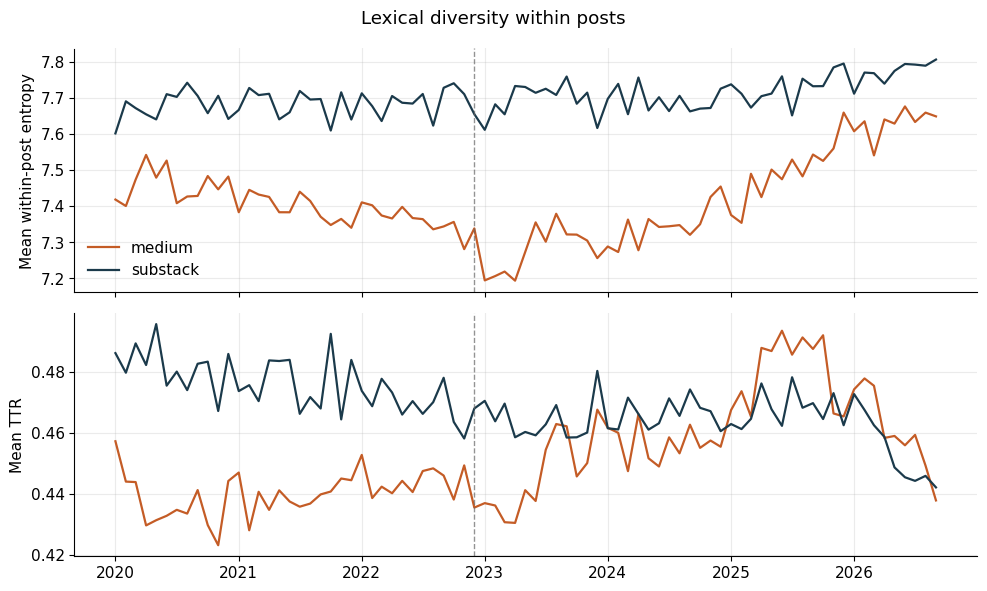

,mean_entropy_ai,mean_entropy_human,mean_ttr_ai,mean_ttr_human
platform,,,,
medium,7.4323,7.3696,0.4631,0.4516
substack,7.6675,7.7081,0.4724,0.4601


In [3]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for ax, col, title in zip(axes, ["mean_entropy", "mean_ttr"], ["Mean within-post entropy", "Mean TTR"]):
    for platform, g in month.groupby("platform"):
        ax.plot(g["date"], g[col], label=platform, color=COLORS[platform], lw=1.6)
    ax.axvline(pd.Timestamp("2022-12-01"), color="#666", ls="--", lw=1, alpha=0.7)
    ax.set_ylabel(title)
axes[0].legend(frameon=False)
fig.suptitle("Vocabulary inside posts")
fig.tight_layout()
plt.show()

# AI vs human within-post (post-break months with enough of both)
q = month[(month.year_month >= "2023-01") & (month.n_sample_ai >= 30) & (month.n_sample_human >= 30)]
cmp = q.groupby("platform")[
    ["mean_entropy_ai", "mean_entropy_human", "mean_ttr_ai", "mean_ttr_human"]
].mean().round(4)
display(cmp)


## 3. Word overlap across posts

Jaccard is basically “how much of the word set is shared between two posts.” Top-100 type mass is “how much of the month’s wording sits in the most common 100 words.” If posts are becoming more alike, both should go up.


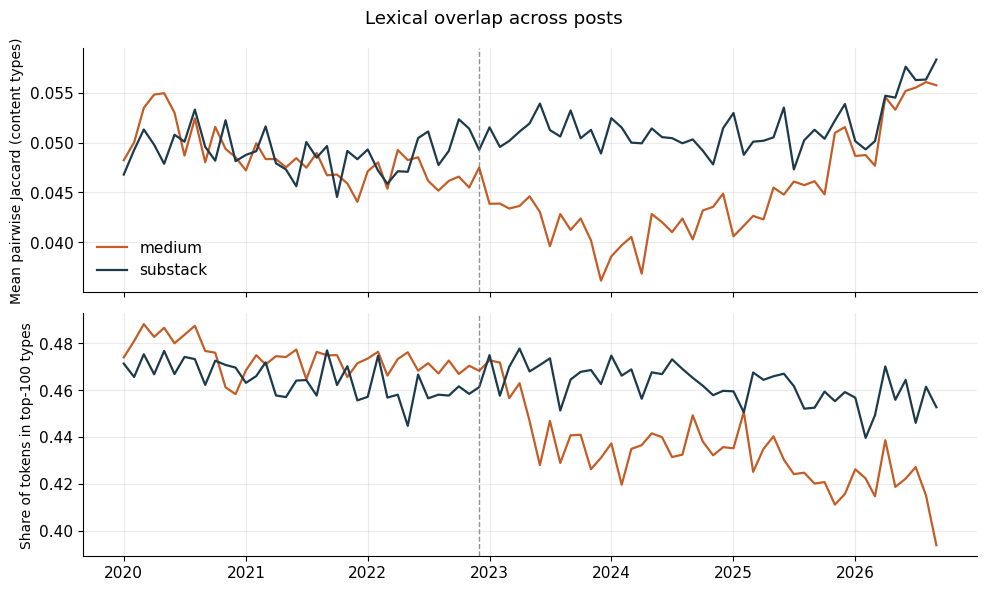

,mean_jaccard_ai,mean_jaccard_human,top100_type_mass_ai,top100_type_mass_human
platform,,,,
medium,0.0486,0.0455,0.4150,0.4711
substack,0.0491,0.0534,0.4227,0.4725


In [4]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for ax, col, title in zip(
    axes,
    ["mean_jaccard", "top100_type_mass"],
    ["Mean pairwise Jaccard (content types)", "Share of tokens in top-100 types"],
):
    for platform, g in month.groupby("platform"):
        ax.plot(g["date"], g[col], label=platform, color=COLORS[platform], lw=1.6)
    ax.axvline(pd.Timestamp("2022-12-01"), color="#666", ls="--", lw=1, alpha=0.7)
    ax.set_ylabel(title, fontsize=10)
axes[0].legend(frameon=False)
fig.suptitle("Word overlap across posts")
fig.tight_layout()
plt.show()

q = month[(month.year_month >= "2023-01") & (month.n_sample_ai >= 30) & (month.n_sample_human >= 30)]
display(q.groupby("platform")[["mean_jaccard_ai", "mean_jaccard_human", "top100_type_mass_ai", "top100_type_mass_human"]].mean().round(4))


## 4. Meaning across posts

We turn the month sample into TF–IDF, compress it with LSA, then measure how far posts sit from each other (and from the month’s center). Lower distance = more alike = more homogenization on this measure.


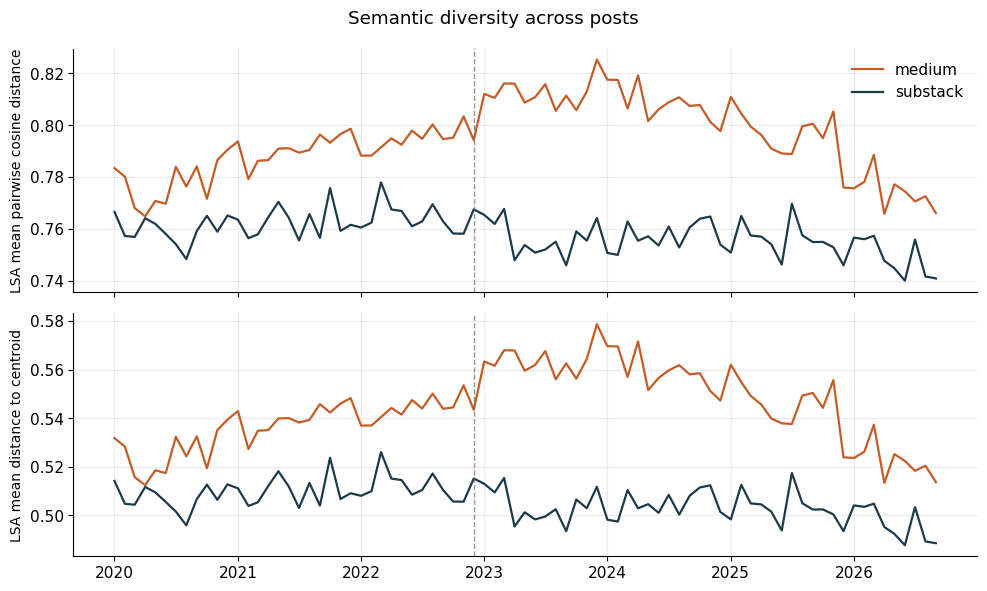

,lsa_pairwise_distance_ai,lsa_pairwise_distance_human,lsa_centroid_distance_ai,lsa_centroid_distance_human
platform,,,,
medium,0.7992,0.7898,0.5494,0.5387
substack,0.7828,0.7494,0.5319,0.4970


In [5]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for ax, col, title in zip(
    axes,
    ["lsa_pairwise_distance", "lsa_centroid_distance"],
    ["LSA mean pairwise cosine distance", "LSA mean distance to centroid"],
):
    for platform, g in month.groupby("platform"):
        ax.plot(g["date"], g[col], label=platform, color=COLORS[platform], lw=1.6)
    ax.axvline(pd.Timestamp("2022-12-01"), color="#666", ls="--", lw=1, alpha=0.7)
    ax.set_ylabel(title, fontsize=10)
axes[0].legend(frameon=False)
fig.suptitle("How far apart posts sit (LSA)")
fig.tight_layout()
plt.show()

q = month[(month.year_month >= "2023-01") & (month.n_sample_ai >= 30) & (month.n_sample_human >= 30)]
display(q.groupby("platform")[
    ["lsa_pairwise_distance_ai", "lsa_pairwise_distance_human",
     "lsa_centroid_distance_ai", "lsa_centroid_distance_human"]
].mean().round(4))


## Pre / post, and correlation with AI share


In [6]:
meas = [
    "share_ai", "topic_entropy", "topic_effective_n", "topic_hhi",
    "mean_entropy", "mean_ttr", "mean_jaccard", "top100_type_mass",
    "lsa_pairwise_distance", "lsa_centroid_distance",
]
display(month.groupby(["platform", "period"])[meas].mean().round(4))

print("corr with monthly AI share")
for platform, g in month.groupby("platform"):
    print("\n", platform)
    print(g[meas].corr()["share_ai"].drop("share_ai").round(3).to_string())


share_ai  topic_entropy  topic_effective_n  topic_hhi  \
platform period                                                          
medium   post      0.6161         2.1774             4.5271     0.3530   
         pre       0.0051         2.1277             4.3765     0.3706   
substack post      0.1695         2.6273             6.1802     0.2379   
         pre       0.0016         2.5460             5.8437     0.2429   

                 mean_entropy  mean_ttr  mean_jaccard  top100_type_mass  \
platform period                                                           
medium   post          7.4213    0.4604        0.0449            0.4340   
         pre           7.4065    0.4401        0.0485            0.4739   
substack post          7.7166    0.4637        0.0514            0.4623   
         pre           7.6830    0.4762        0.0490            0.4647   

                 lsa_pairwise_distance  lsa_centroid_distance  
platform period                                                
medium   post                   0.7994                 0.5494  
         pre                    0.7875                 0.5363  
substack post                   0.7552                 0.5027  
         pre                    0.7621                 0.5097

Pearson corr with monthly share_ai

 medium
topic_entropy            0.416
topic_effective_n        0.411
topic_hhi               -0.447
mean_entropy             0.286
mean_ttr                 0.734
mean_jaccard            -0.265
top100_type_mass        -0.923
lsa_pairwise_distance    0.247
lsa_centroid_distance    0.252

 substack
topic_entropy            0.316
topic_effective_n        0.311
topic_hhi                0.195
mean_entropy             0.557
mean_ttr                -0.464
mean_jaccard             0.454
top100_type_mass        -0.405
lsa_pairwise_distance   -0.470
lsa_centroid_distance   -0.468


## What it looks like

**Medium.** As AI share rises, we mostly do *not* see classic homogenization. Topic entropy goes up a bit. Word overlap and top-100 concentration go down. LSA distances edge up. Inside posts, entropy/TTR do not collapse. Comparing AI vs human after the break is mixed — AI posts share words a little more, but they are not tighter in LSA space.

**Substack.** Smaller AI rise, but the across-post text measures look more like homogenization: Jaccard rises with AI share, and LSA distances fall. Topic entropy still does not really collapse. Inside the AI group, posts are still a bit more spread in LSA than human posts, so some of the monthly squeeze may just be the mix changing.

**Caveats.** LSA is still bag-of-words, not real embeddings. Jaccard ignores order. `topic_code` is only ~9–10 NMF topics. Detector scores are not ground truth. A cleaner next step would be sentence embeddings and looking inside topics / creators over time.
